# Mesh 3-pt calculations

This package includes mesh-based bispectrum estimation.

## Bispectrum from mesh

In [6]:
# Let's create some mock mesh!
import jax
from jax import numpy as jnp
from romanpower import MeshAttrs, Mesh2SpectrumPole, Mesh2SpectrumPoles, generate_anisotropic_gaussian_mesh
meshsize = 64

def get_theory(kmax=0.3, dk=0.001):
    # Return theory power spectrum
    from cosmoprimo.fiducial import DESI
    cosmo = DESI(engine='eisenstein_hu')
    z = 1.
    pk1d = cosmo.get_fourier().pk_interpolator().to_1d(z=z)
    ellsin = (0, 2, 4)
    edgesin = jnp.arange(0., kmax, dk)
    edgesin = jnp.column_stack([edgesin[:-1], edgesin[1:]])
    kin = (edgesin[..., 0] + edgesin[..., 1]) / 2.
    f, b = cosmo.growth_rate(z), 1.5
    beta = f / b
    shotnoise = (1e-3)**(-1)
    pk = pk1d(kin)
    poles = [(1. + 2. / 3. * beta + 1. / 5. * beta ** 2) * pk + shotnoise,
            0.99 * (4. / 3. * beta + 4. / 7. * beta ** 2) * pk,
            8. / 35 * beta ** 2 * pk]

    theory = []
    for ell, value in zip(ellsin, poles):
        theory.append(Mesh2SpectrumPole(k=kin, k_edges=edgesin, num_raw=value, num_shotnoise=shotnoise * jnp.ones_like(kin) * (ell == 0), ell=ell))
    return Mesh2SpectrumPoles(theory)

mattrs = MeshAttrs(boxsize=1000., meshsize=meshsize)
poles = get_theory(4 * mattrs.knyq.max())
mesh = generate_anisotropic_gaussian_mesh(mattrs, poles, los='z', seed=68, order=1, unitary_amplitude=True)
print(mesh)

RealMeshField(attrs=MeshAttrs(meshsize=staticarray([64, 64, 64], dtype=int32), boxsize=Array([1000., 1000., 1000.], dtype=float64), boxcenter=Array([0., 0., 0.], dtype=float64), dtype=dtype('float64'), fft_backend='jaxdecomp'))


In [7]:
# Now compute bispectrum
from romanpower import compute_mesh3_spectrum, BinMesh3SpectrumPoles

# This can be instantiated once for many bispectrum calculations as long as they share the same MeshAttrs
bin = BinMesh3SpectrumPoles(mattrs, edges={'step': 0.02}, basis='scoccimarro', ells=[0, 2], buffer_size=10)

# One can jit the bispectrum calculation
compute = jax.jit(compute_mesh3_spectrum, static_argnames=['los'])

bk = compute(mesh, bin=bin, los='z')

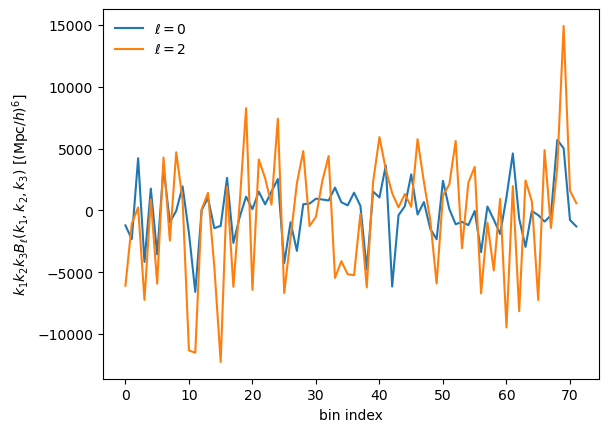

In [8]:
bk.plot(show=True);

In [9]:
# Interlude: the measurement
bk2 = bk.select(k=slice(0, None, 2))  # rebin by a factor 2
bk2 = bk2.select(k=(0.05, 0.2))  # select 0.05 <= k [h/Mpc] < 0.2
bk2 = bk2.get(ells=[0, 2])  # restrict to ell = 0, 2
bk2.get(0).value()  # to view as an array
bk2.get(0).coords('k')  # k for ell = 0
bk2.get(0).values('nmodes')  # number of modes
bk2.get(0).edges('k');  # edges

## Bispectrum from particles (FKP)

In [10]:
# Let's create some mock particles!
from romanpower import generate_uniform_particles

mattrs = MeshAttrs(boxsize=1000., meshsize=meshsize, boxcenter=700.)
poles = get_theory(4 * mattrs.knyq.max())
# With local line-of-sight
mmesh = generate_anisotropic_gaussian_mesh(mattrs, poles, los='local', seed=68, order=1, unitary_amplitude=True)

# Generate particles in smaller volume
pattrs = mattrs.clone(boxsize=500.)
size = int(1e6)
data = generate_uniform_particles(pattrs, size, seed=42)
# Set weights = 1 + delta
data = data.clone(weights=1. + mmesh.read(data.positions, resampler='cic', compensate=True))

# Now randoms
randoms = generate_uniform_particles(pattrs, 2 * size, seed=43)

In [11]:
from romanpower import FKPField, compute_fkp3_normalization, compute_fkp3_shotnoise, get_mesh_attrs

# Define MeshAttrs from positions
mattrs = get_mesh_attrs(data.positions, randoms.positions, boxpad=2., meshsize=meshsize)

# Tip: can be done once for many B(k) evaluations
bin = BinMesh3SpectrumPoles(mattrs, edges={'step': 0.02}, basis='scoccimarro', ells=[0, 2], buffer_size=10)

fkp = FKPField(data, randoms, attrs=mattrs)
norm, num_shotnoise = compute_fkp3_normalization(fkp, bin=bin), compute_fkp3_shotnoise(fkp, bin=bin, resampler='tsc', interlacing=3, compensate=True)
# Paint particles to mesh
mesh = fkp.paint(resampler='tsc', interlacing=3, compensate=True, out='real')
del fkp
# Then compute power spectrum
# One can jit the function
compute = jax.jit(compute_mesh3_spectrum, static_argnames=['los'])
bk = compute(mesh, bin=bin, los='local')
# Add the normalization and shot noise information
bk = bk.clone(norm=norm, num_shotnoise=num_shotnoise)

/pscratch/sd/w/willlake/desi/conda/envs/DESI-MG/lib/python3.13/site-packages/jax/_src/interpreters/mlir.py:1365: UserWarning: Some donated buffers were not usable: complex128[64,64,64], float64[3], complex128[64,64,64].
See an explanation at https://docs.jax.dev/en/latest/faq.html#buffer-donation.
  warnings.warn("Some donated buffers were not usable:"


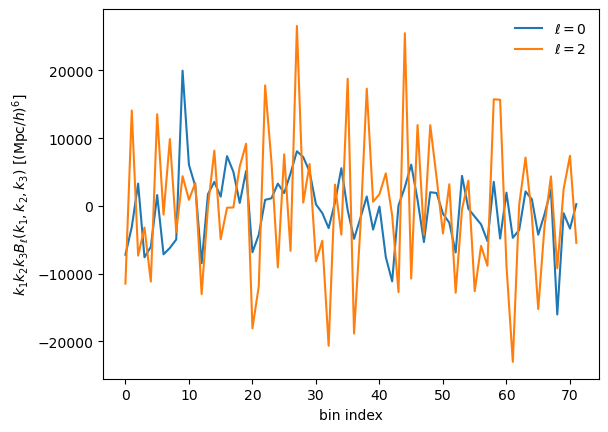

In [12]:
bk.plot(show=True);